In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score
from sklearn.ensemble import HistGradientBoostingClassifier
import warnings
warnings.filterwarnings('ignore')

train = pd.read_csv('train.csv')
test  = pd.read_csv('test.csv')
sub   = pd.read_csv('sample_submission.csv')

print("Train shape:", train.shape)
print("Test shape :", test.shape)
print("\nTarget distribution:")
print(train['Irrigation_Need'].value_counts(normalize=True).round(4))
print(train.head())

Train shape: (630000, 21)
Test shape : (270000, 20)

Target distribution:
Irrigation_Need
Low       0.5872
Medium    0.3795
High      0.0333
Name: proportion, dtype: float64
   id Soil_Type  Soil_pH  Soil_Moisture  Organic_Carbon  \
0   0     Loamy     4.92          32.58            1.01   
1   1      Clay     7.08          56.61            0.44   
2   2      Clay     5.69          27.71            0.81   
3   3     Sandy     5.65          13.32            1.33   
4   4      Clay     7.96          59.14            0.38   

   Electrical_Conductivity  Temperature_C  Humidity  Rainfall_mm  \
0                     3.05          15.01     50.61       725.99   
1                     2.00          22.92     67.86       985.66   
2                     2.83          26.97     92.22      2201.70   
3                     0.87          13.32     61.57      1357.33   
4                     0.96          20.22     91.11      1538.20   

   Sunlight_Hours  ...  Crop_Type Crop_Growth_Stage  Season Ir

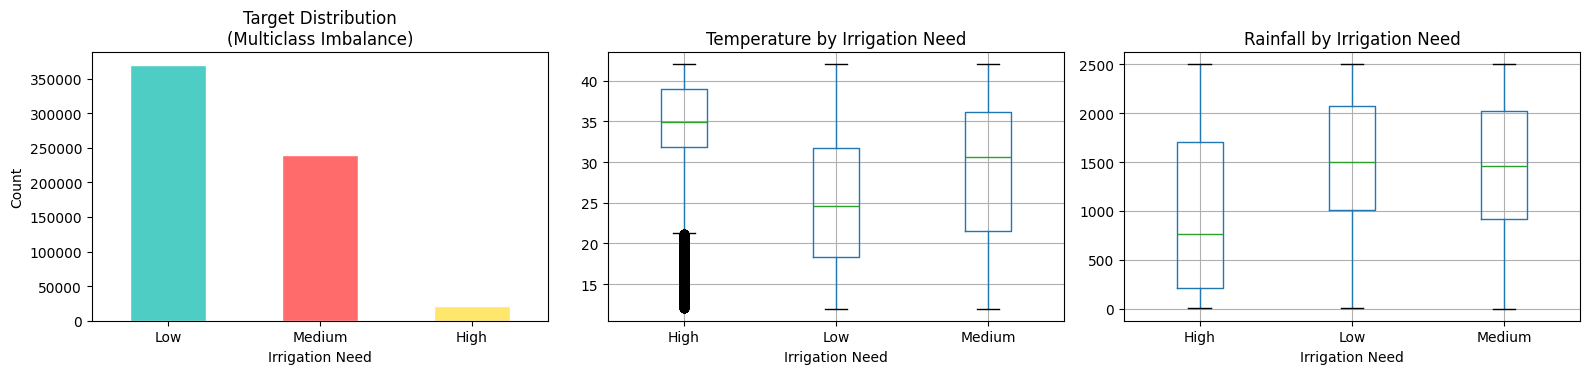

Plot saved!


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Target distribution
train['Irrigation_Need'].value_counts().plot.bar(
    color=['#4ECDC4','#FF6B6B','#FFE66D'],
    ax=axes[0], edgecolor='white'
)
axes[0].set_title('Target Distribution\n(Multiclass Imbalance)', fontsize=12)
axes[0].set_xlabel('Irrigation Need')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

# Temperature vs Irrigation Need
train.boxplot(column='Temperature_C', by='Irrigation_Need', ax=axes[1])
axes[1].set_title('Temperature by Irrigation Need', fontsize=12)
axes[1].set_xlabel('Irrigation Need')

# Rainfall vs Irrigation Need
train.boxplot(column='Rainfall_mm', by='Irrigation_Need', ax=axes[2])
axes[2].set_title('Rainfall by Irrigation Need', fontsize=12)
axes[2].set_xlabel('Irrigation Need')

plt.suptitle('')
plt.tight_layout()
plt.savefig('eda_irrigation.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")

In [3]:
def feature_engineering(df):
    df = df.copy()

    # Water stress index — semakin kering → butuh lebih banyak irigasi
    df['water_stress']        = df['Temperature_C'] / (df['Rainfall_mm'] + 1)
    df['moisture_deficit']    = df['Temperature_C'] - df['Soil_Moisture']

    # Evapotranspiration proxy — kombinasi suhu + angin + sinar matahari
    df['evapotranspiration']  = (df['Temperature_C'] * df['Sunlight_Hours']) / (df['Humidity'] + 1)
    df['wind_heat_index']     = df['Wind_Speed_kmh'] * df['Temperature_C']

    # Soil water retention capacity
    df['soil_water_capacity'] = df['Soil_Moisture'] * df['Organic_Carbon']
    df['ph_moisture']         = df['Soil_pH'] * df['Soil_Moisture']

    # Previous irrigation efficiency
    df['irrigation_per_area'] = df['Previous_Irrigation_mm'] / (df['Field_Area_hectare'] + 1)
    df['rain_vs_prev_irrig']  = df['Rainfall_mm'] / (df['Previous_Irrigation_mm'] + 1)

    # Humidity-temperature interaction
    df['heat_humidity']       = df['Temperature_C'] * (1 - df['Humidity'] / 100)

    # Mulching binary
    df['mulching_bin']        = (df['Mulching_Used'] == 'Yes').astype(int)

    return df

train = feature_engineering(train)
test  = feature_engineering(test)
print("Features after engineering:", train.shape[1])
print(train.head())

Features after engineering: 31
   id Soil_Type  Soil_pH  Soil_Moisture  Organic_Carbon  \
0   0     Loamy     4.92          32.58            1.01   
1   1      Clay     7.08          56.61            0.44   
2   2      Clay     5.69          27.71            0.81   
3   3     Sandy     5.65          13.32            1.33   
4   4      Clay     7.96          59.14            0.38   

   Electrical_Conductivity  Temperature_C  Humidity  Rainfall_mm  \
0                     3.05          15.01     50.61       725.99   
1                     2.00          22.92     67.86       985.66   
2                     2.83          26.97     92.22      2201.70   
3                     0.87          13.32     61.57      1357.33   
4                     0.96          20.22     91.11      1538.20   

   Sunlight_Hours  ...  water_stress moisture_deficit evapotranspiration  \
0            5.90  ...      0.020647           -17.57           1.715927   
1            6.98  ...      0.023230           -33.69

In [4]:
# Encode target: Low=0, Medium=1, High=2
label_map = {'Low': 0, 'Medium': 1, 'High': 2}
train['target'] = train['Irrigation_Need'].map(label_map)

# Encode categoricals
cat_cols = ['Soil_Type', 'Crop_Type', 'Crop_Growth_Stage', 'Season',
            'Irrigation_Type', 'Water_Source', 'Mulching_Used', 'Region']

enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
enc.fit(pd.concat([train[cat_cols], test[cat_cols]], axis=0))
train[cat_cols] = enc.transform(train[cat_cols])
test[cat_cols]  = enc.transform(test[cat_cols])

FEATURES = [
    'Soil_Type', 'Soil_pH', 'Soil_Moisture', 'Organic_Carbon',
    'Electrical_Conductivity', 'Temperature_C', 'Humidity',
    'Rainfall_mm', 'Sunlight_Hours', 'Wind_Speed_kmh',
    'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Irrigation_Type',
    'Water_Source', 'Field_Area_hectare', 'Mulching_Used',
    'Previous_Irrigation_mm', 'Region',
    # engineered
    'water_stress', 'moisture_deficit', 'evapotranspiration',
    'wind_heat_index', 'soil_water_capacity', 'ph_moisture',
    'irrigation_per_area', 'rain_vs_prev_irrig', 'heat_humidity', 'mulching_bin'
]

X      = train[FEATURES]
y      = train['target']
X_test = test[FEATURES]

print(f"Total features : {len(FEATURES)}")
print(f"Class distribution: {y.value_counts(normalize=True).round(4).to_dict()}")

Total features : 29
Class distribution: {0: 0.5872, 1: 0.3795, 2: 0.0333}


In [5]:
params = dict(
    max_iter=500,
    learning_rate=0.08,
    max_leaf_nodes=63,
    min_samples_leaf=80,
    l2_regularization=1.0,
    max_bins=255,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=42,
    verbose=0,
    class_weight='balanced',  # handle imbalance Low/Med/High
)

# Subsample 150K — cukup representatif
np.random.seed(42)
sample_idx = np.random.choice(len(train), 150000, replace=False)
X_s, y_s   = X.iloc[sample_idx], y.iloc[sample_idx]

N_SPLITS  = 3
skf       = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
oof_preds = np.zeros(len(X_s), dtype=int)
models    = []

print(f"\n{'='*55}")
print(f"  3-Fold CV — HistGradientBoostingClassifier")
print(f"  Features : {len(FEATURES)}")
print(f"  Classes  : Low(0) / Medium(1) / High(2)")
print(f"{'='*55}")

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_s, y_s), 1):
    m = HistGradientBoostingClassifier(**params)
    m.fit(X_s.iloc[tr_idx], y_s.iloc[tr_idx])
    oof_preds[val_idx] = m.predict(X_s.iloc[val_idx])
    models.append(m)

    fold_acc = accuracy_score(y_s.iloc[val_idx], oof_preds[val_idx])
    fold_f1  = f1_score(y_s.iloc[val_idx], oof_preds[val_idx], average='macro')
    print(f"  Fold {fold} | Accuracy: {fold_acc:.5f} | Macro F1: {fold_f1:.5f} | Iters: {m.n_iter_}")

overall_acc = accuracy_score(y_s, oof_preds)
overall_f1  = f1_score(y_s, oof_preds, average='macro')
print(f"{'='*55}")
print(f"  Overall Accuracy : {overall_acc:.5f}")
print(f"  Overall Macro F1 : {overall_f1:.5f}")
print(f"{'='*55}")


  3-Fold CV — HistGradientBoostingClassifier
  Features : 29
  Classes  : Low(0) / Medium(1) / High(2)
  Fold 1 | Accuracy: 0.98320 | Macro F1: 0.96395 | Iters: 58
  Fold 2 | Accuracy: 0.98306 | Macro F1: 0.96306 | Iters: 60
  Fold 3 | Accuracy: 0.98208 | Macro F1: 0.95993 | Iters: 67
  Overall Accuracy : 0.98278
  Overall Macro F1 : 0.96232


In [6]:
from scipy import stats

# Majority vote dari 3 fold models
all_preds = np.array([m.predict(X_test) for m in models])
test_preds_num = stats.mode(all_preds, axis=0)[0]

# Decode back ke label
reverse_map = {0: 'Low', 1: 'Medium', 2: 'High'}
sub['Irrigation_Need'] = [reverse_map[p] for p in test_preds_num]

sub.to_csv('submission.csv', index=False)
print("Submission preview:")
print(sub.head(10))
print(f"\nPrediction distribution:")
print(sub['Irrigation_Need'].value_counts(normalize=True).round(4))

from google.colab import files
files.download('submission.csv')

Submission preview:
       id Irrigation_Need
0  630000             Low
1  630001             Low
2  630002             Low
3  630003             Low
4  630004             Low
5  630005          Medium
6  630006             Low
7  630007          Medium
8  630008            High
9  630009             Low

Prediction distribution:
Irrigation_Need
Low       0.5912
Medium    0.3749
High      0.0339
Name: proportion, dtype: float64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>